# M2 · Tim Sepaket · T1-C Detektor Ringan (TXL-PBC)
Notebook ini mencakup: EDA, split resmi tersimpan, pemeriksaan duplikat (perceptual hash), pemeriksaan visual label, baseline **R1 (YOLOv8n, 640 px, seed 42)**, evaluasi (mAP + galat hitung sel) dan latensi CPU.

**Cara pakai:** Runtime → Change runtime type → **T4 GPU**, lalu jalankan sel dari atas ke bawah.
Set uji **tidak dipakai** di notebook ini (hanya untuk R8 di akhir proyek).

In [1]:
!pip -q install ultralytics torchmetrics pycocotools imagehash openpyxl
import os, glob, json, random, time, itertools
import numpy as np, pandas as pd, torch, imagehash
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
NAMES = ['WBC', 'RBC', 'Platelets']
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'tidak ada (ganti runtime ke T4)')

GPU: Tesla T4


In [2]:
# Simpan hasil ke Google Drive supaya tidak hilang saat sesi Colab terputus
try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT = '/content/drive/MyDrive/Sepaket_T1C'
except Exception:
    OUT = '/content/Sepaket_T1C'
os.makedirs(OUT, exist_ok=True)
print('Output:', OUT)

Output: /content/Sepaket_T1C


In [3]:
# Unduh TXL-PBC (MIT). Dataset TIDAK boleh disebarkan ulang di repositori; cukup skrip unduh ini.
if not os.path.exists('/content/TXL-PBC_Dataset'):
    !git clone --depth 1 https://github.com/lugan113/TXL-PBC_Dataset.git /content/TXL-PBC_Dataset
ROOT = '/content/TXL-PBC_Dataset/TXL-PBC'
for sp in ['train', 'val', 'test']:
    print(sp, len(os.listdir(f'{ROOT}/images/{sp}')), 'citra')

Cloning into '/content/TXL-PBC_Dataset'...
remote: Enumerating objects: 2546, done.
remote: Counting objects: 100% (2546/2546), done.
remote: Compressing objects: 100% (2542/2542), done.
remote: Total 2546 (delta 4), reused 2539 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (2546/2546), 42.99 MiB | 12.99 MiB/s, done.
Resolving deltas: 100% (4/4), done.
train 882 citra
val 252 citra
test 126 citra


## 1. EDA

In [4]:
meta = pd.read_excel(f'{ROOT}/metadata_file.xlsx')
SRC = dict(zip(meta.New_Image_Name.str.rsplit('.', n=1).str[0], meta.Source_Dataset))

def read_gt(img_path):
    """Baca label YOLO -> kotak xyxy (piksel) dan kelas."""
    W, H = Image.open(img_path).size
    lp = img_path.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
    boxes, labels = [], []
    if os.path.exists(lp):
        for ln in open(lp):
            v = ln.split()
            if len(v) < 5: continue
            c = int(v[0]); cx, cy, w, h = map(float, v[1:5])
            boxes.append([(cx-w/2)*W, (cy-h/2)*H, (cx+w/2)*W, (cy+h/2)*H]); labels.append(c)
    return np.array(boxes).reshape(-1, 4), np.array(labels, dtype=int)

rows, imgs = [], []
for sp in ['train', 'val', 'test']:
    for ip in sorted(glob.glob(f'{ROOT}/images/{sp}/*')):
        stem = os.path.splitext(os.path.basename(ip))[0]
        W, H = Image.open(ip).size
        b, l = read_gt(ip)
        for (x1, y1, x2, y2), c in zip(b, l):
            rows.append((sp, stem, NAMES[c], x2-x1, y2-y1, (x2-x1)*(y2-y1)))
        imgs.append((sp, stem, ip, W, H, len(l), SRC.get(stem, '?')))
boxes = pd.DataFrame(rows, columns=['split', 'img', 'cls', 'w', 'h', 'area'])
im = pd.DataFrame(imgs, columns=['split', 'img', 'path', 'W', 'H', 'n', 'source'])

print('Citra:', len(im), '| Kotak:', len(boxes))
display(boxes.groupby(['split', 'cls']).size().unstack(fill_value=0)[NAMES])
display(im.n.describe().round(2))
display(boxes.groupby('cls').area.describe().round(0))
display(im.groupby(['split', 'source']).size().unstack(fill_value=0))
print('Platelet kecil (<32x32 px, definisi COCO):', round((boxes[boxes.cls=='Platelets'].area < 32*32).mean(), 3))

Citra: 1260 | Kotak: 18143


cls,WBC,RBC,Platelets
split,,,
test,133,1699,49
train,908,11220,382
val,257,3383,112


,n
count,1260.00
mean,14.40
std,4.68
min,4.00
25%,11.00
50%,14.00
75%,17.00
max,32.00


,count,mean,std,min,25%,50%,75%,max
cls,,,,,,,,
Platelets,543.0,1395.0,1031.0,255.0,866.0,1120.0,1599.0,11990.0
RBC,16302.0,9722.0,6152.0,1353.0,5112.0,7560.0,13250.0,94743.0
WBC,1298.0,41207.0,28119.0,4760.0,17708.0,33893.0,64524.0,140400.0


source,BCCD,BCDD,PBC,Raabin-WBC
split,,,,
test,18,14,50,44
train,101,70,353,358
val,41,16,97,98


Platelet kecil (<32x32 px, definisi COCO): 0.436


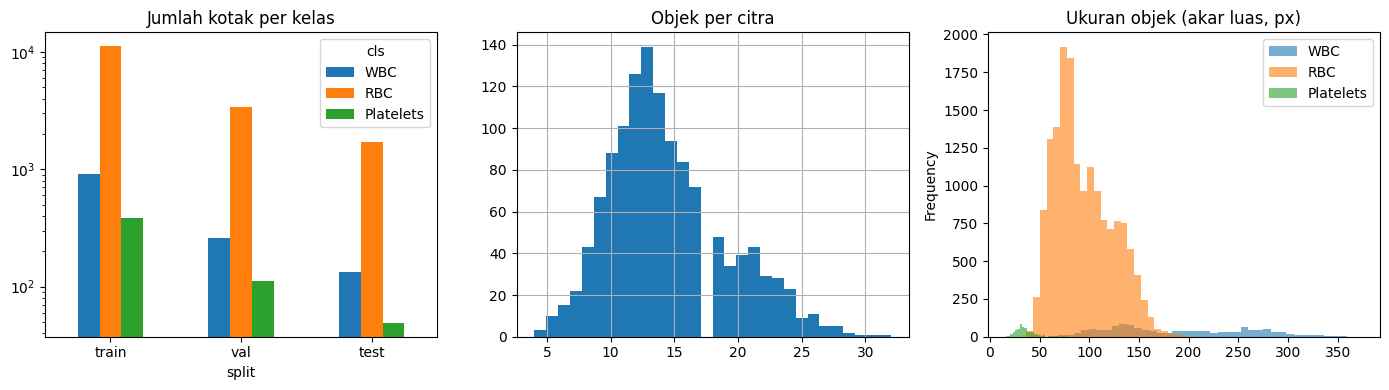

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
boxes.groupby(['split', 'cls']).size().unstack()[NAMES].loc[['train','val','test']].plot.bar(ax=ax[0], rot=0, logy=True); ax[0].set_title('Jumlah kotak per kelas')
im.n.hist(bins=30, ax=ax[1]); ax[1].set_title('Objek per citra')
for c in NAMES: np.sqrt(boxes[boxes.cls==c].area).plot.hist(bins=40, alpha=.6, ax=ax[2], label=c)
ax[2].set_title('Ukuran objek (akar luas, px)'); ax[2].legend()
plt.tight_layout(); plt.savefig(f'{OUT}/eda.png', dpi=150); plt.show()

## 2. Split resmi tersimpan (seed 42)
TXL-PBC sudah menyediakan split resmi, jadi kita pakai itu dan menyimpan daftar nama berkasnya untuk repositori.

In [6]:
for sp in ['train', 'val', 'test']:
    names = [os.path.basename(p) for p in im[im.split == sp].path]
    open(f'{OUT}/split_{sp}.txt', 'w').write('\n'.join(names) + '\n')
    print(sp, len(names))

train 882
val 252
test 126


## 3. Pemeriksaan duplikat (perceptual hash)
Jarak Hamming pHash antara tiap citra val/test dan seluruh citra latih. Jarak kecil = citra hampir sama.

In [7]:
im['ph'] = [imagehash.phash(Image.open(p)) for p in im.path]
tr = im[im.split == 'train']
res = []
for sp in ['val', 'test']:
    for _, r in im[im.split == sp].iterrows():
        d, nm = min(((r.ph - t.ph), t.img) for _, t in tr.iterrows())
        res.append((sp, r.img, int(d), nm))
dup = pd.DataFrame(res, columns=['split', 'img', 'min_dist', 'nearest_train']).sort_values('min_dist')
dup.to_csv(f'{OUT}/phash_val_test_vs_train.csv', index=False)
for sp in ['val', 'test']:
    d = dup[dup.split == sp]
    print(f'{sp}: n={len(d)} | jarak 0: {(d.min_dist==0).sum()} | <=4: {(d.min_dist<=4).sum()} | <=8: {(d.min_dist<=8).sum()} | terkecil: {d.min_dist.min()}')
dup.head(5)

val: n=252 | jarak 0: 0 | <=4: 1 | <=8: 2 | terkecil: 4
test: n=126 | jarak 0: 0 | <=4: 0 | <=8: 0 | terkecil: 10


,split,img,min_dist,nearest_train
27,val,1877ecbbcd8b5b9eabf534aaf3f583e3,4,3d07f563f41d569bb6b50ca695aae52f
37,val,20723236a89850f295e6d06759de2e5a,6,796a64020a9e5b5d8c3fca6b5ce5bf96
367,test,eef539ef286e50e3888796e27c391b89,10,b9a2a0048ebd585794f6a1da21153506
61,val,3d7cae6484ce5bdb97997d71d4c423cd,10,de4e9c6117185616bfe1bbfee4423b75
136,val,81e0a9f084f755168436882c1dd721c5,10,35f7687602635fd4a0ee34687dbd115e


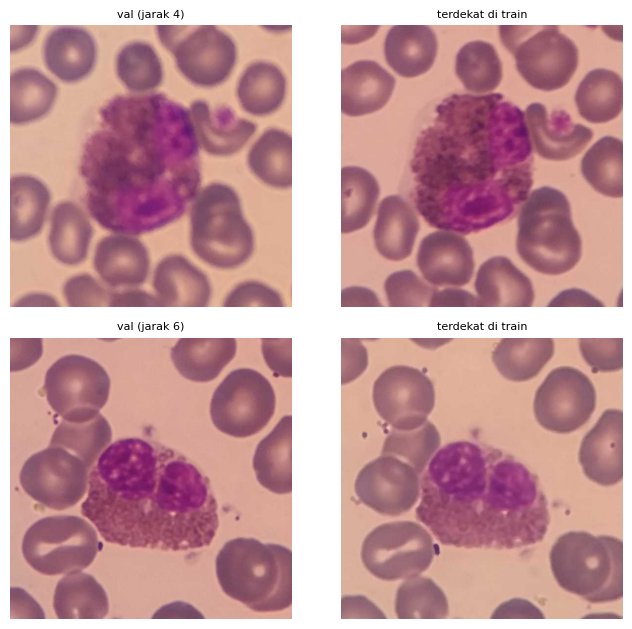

In [8]:
# Lihat pasangan dengan jarak terkecil secara visual (jarak <= 8 dicek manual)
cand = dup[dup.min_dist <= 8].head(4)
if len(cand):
    fig, ax = plt.subplots(len(cand), 2, figsize=(7, 3.2*len(cand)), squeeze=False)
    for i, (_, r) in enumerate(cand.iterrows()):
        a = im[im.img == r.img].path.iloc[0]; b = im[im.img == r.nearest_train].path.iloc[0]
        ax[i,0].imshow(Image.open(a)); ax[i,0].set_title(f'{r.split} (jarak {r.min_dist})', fontsize=8)
        ax[i,1].imshow(Image.open(b)); ax[i,1].set_title('terdekat di train', fontsize=8)
        ax[i,0].axis('off'); ax[i,1].axis('off')
    plt.tight_layout(); plt.show()

## 4. Pemeriksaan visual label (20 citra, acak seed 42)

In [9]:
COL = {0: 'red', 1: 'lime', 2: 'cyan'}
rng = random.Random(SEED)
sample = rng.sample(list(im[im.split == 'train'].path), 20)
fig, ax = plt.subplots(4, 5, figsize=(16, 13))
for a, p in zip(ax.ravel(), sample):
    img = Image.open(p).convert('RGB'); d = ImageDraw.Draw(img)
    b, l = read_gt(p)
    for (x1, y1, x2, y2), c in zip(b, l): d.rectangle([x1, y1, x2, y2], outline=COL[c], width=2)
    a.imshow(img); a.axis('off')
plt.suptitle('merah=WBC, hijau=RBC, cyan=Platelets'); plt.tight_layout(); plt.savefig(f'{OUT}/label_check.png', dpi=110); plt.show()

Output hidden; open in https://colab.research.google.com to view.

## 5. Baseline R1: YOLOv8n, 640 px, seed 42
Augmentasi warna dibatasi (hsv_h=0, hsv_s/v kecil) karena warna membawa informasi pewarnaan; flip dan skala tetap aktif.

In [10]:
YAML = f'{OUT}/txl_pbc.yaml'
open(YAML, 'w').write(f"path: {ROOT}\ntrain: images/train\nval: images/val\ntest: images/test\nnc: 3\nnames: {NAMES}\n")

from ultralytics import YOLO
RUN = 'R1_yolov8n_640_s42'
model = YOLO('yolov8n.pt')   # bobot pralatih COCO
t0 = time.time()
model.train(data=YAML, imgsz=640, epochs=50, patience=15, batch=16, seed=SEED, deterministic=True,
            hsv_h=0.0, hsv_s=0.2, hsv_v=0.2, flipud=0.5, fliplr=0.5,
            project=f'{OUT}/runs', name=RUN, exist_ok=True, workers=2, device=DEVICE)
gpu_hours = (time.time() - t0) / 3600
print(f'Waktu latih: {gpu_hours:.2f} jam GPU')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Sepaket_T1C/txl_pbc.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.

## 6. Evaluasi pada set validasi (alat yang sama untuk semua model: torchmetrics)

In [11]:
from torchmetrics.detection import MeanAveragePrecision

BEST = f'{OUT}/runs/{RUN}/weights/best.pt'
m = YOLO(BEST)

def load_split(split):
    files = sorted(glob.glob(f'{ROOT}/images/{split}/*'))
    gts = []
    for f in files:
        b, l = read_gt(f)
        gts.append(dict(boxes=torch.tensor(b, dtype=torch.float32).reshape(-1, 4), labels=torch.tensor(l, dtype=torch.long)))
    return files, gts

def predict_all(model, files, conf=0.001, imgsz=640, iou=0.7):
    preds = []
    for r in model.predict(files, conf=conf, imgsz=imgsz, iou=iou, verbose=False, stream=True, device=DEVICE):
        b = r.boxes
        preds.append(dict(boxes=b.xyxy.cpu(), scores=b.conf.cpu(), labels=b.cls.cpu().long()))
    return preds

def eval_map(preds, gts):
    mt = MeanAveragePrecision(box_format='xyxy', iou_type='bbox', class_metrics=True)
    mt.update(preds, gts); r = mt.compute()
    return dict(mAP50=float(r['map_50']), mAP50_95=float(r['map']), AP_small=float(r['map_small']),
                AP_per_class={n: float(v) for n, v in zip(NAMES, r['map_per_class'])})

def count_metrics(preds, gts, thr):
    """Galat hitung per citra per kelas. MAPE hanya pada citra dengan GT > 0."""
    out = {}
    for c, n in enumerate(NAMES):
        g = np.array([(d['labels'] == c).sum().item() for d in gts])
        p = np.array([((d['labels'] == c) & (d['scores'] >= thr)).sum().item() for d in preds])
        mae = np.abs(p - g).mean(); nz = g > 0
        mape = (np.abs(p[nz] - g[nz]) / g[nz]).mean() * 100 if nz.any() else float('nan')
        out[n] = dict(MAE=float(mae), MAPE=float(mape))
    return out

val_files, val_gts = load_split('val')
val_preds = predict_all(m, val_files)
map_val = eval_map(val_preds, val_gts)
print(json.dumps(map_val, indent=1))

{
 "mAP50": 0.9767858386039734,
 "mAP50_95": 0.8513853549957275,
 "AP_small": 0.7494679093360901,
 "AP_per_class": {
  "WBC": 0.8939074277877808,
  "RBC": 0.8853916525840759,
  "Platelets": 0.7748570442199707
 }
}


In [12]:
# Pilih ambang confidence untuk penghitungan di set VALIDASI (bukan uji)
sweep = {thr: count_metrics(val_preds, val_gts, thr) for thr in [0.25, 0.4, 0.5]}
for thr, r in sweep.items():
    print(thr, {k: (round(v['MAE'], 3), round(v['MAPE'], 1)) for k, v in r.items()})
BEST_THR = min(sweep, key=lambda t: sweep[t]['RBC']['MAE'])   # kriteria: MAE RBC terendah (acuan hipotesis)
print('Ambang terpilih:', BEST_THR)

0.25 {'WBC': (0.012, 0.6), 'RBC': (3.111, 25.2), 'Platelets': (0.107, 13.5)}
0.4 {'WBC': (0.008, 0.2), 'RBC': (2.214, 18.4), 'Platelets': (0.075, 15.1)}
0.5 {'WBC': (0.008, 0.2), 'RBC': (1.774, 15.1), 'Platelets': (0.075, 15.1)}
Ambang terpilih: 0.5


## 7. Efisiensi: parameter dan latensi CPU (batch 1)

In [13]:
def latency_cpu(weights, files, n=50, warmup=5, imgsz=640):
    mm = YOLO(weights)
    for f in files[:warmup]: mm.predict(f, imgsz=imgsz, device='cpu', verbose=False)
    ts = []
    for f in files[:n]:
        t = time.perf_counter(); mm.predict(f, imgsz=imgsz, device='cpu', verbose=False); ts.append((time.perf_counter() - t) * 1000)
    params = sum(p.numel() for p in mm.model.parameters()) / 1e6
    return float(np.mean(ts)), float(np.std(ts)), params

lat_mean, lat_std, params_m = latency_cpu(BEST, val_files)
print(f'Latensi CPU: {lat_mean:.1f} ± {lat_std:.1f} ms/citra | Parameter: {params_m:.2f} juta')
import platform; print('CPU:', platform.processor() or platform.machine())

Latensi CPU: 111.6 ± 18.6 ms/citra | Parameter: 3.14 juta
CPU: x86_64


## 8. Catat ke log eksperimen

In [14]:
LOG = f'{OUT}/experiment_log.csv'
row = dict(run=RUN, model='YOLOv8n', imgsz=640, seed=SEED, split_eval='val',
           mAP50=map_val['mAP50'], mAP50_95=map_val['mAP50_95'], AP_small=map_val['AP_small'],
           AP_WBC=map_val['AP_per_class']['WBC'], AP_RBC=map_val['AP_per_class']['RBC'], AP_Platelets=map_val['AP_per_class']['Platelets'],
           count_thr=BEST_THR, MAE_WBC=sweep[BEST_THR]['WBC']['MAE'], MAE_RBC=sweep[BEST_THR]['RBC']['MAE'], MAE_Platelets=sweep[BEST_THR]['Platelets']['MAE'],
           MAPE_RBC=sweep[BEST_THR]['RBC']['MAPE'], params_M=params_m, latency_cpu_ms=lat_mean, gpu_hours=gpu_hours)
df = pd.DataFrame([row])
df.to_csv(LOG, mode='a', header=not os.path.exists(LOG), index=False)
df.T

,0
run,R1_yolov8n_640_s42
model,YOLOv8n
imgsz,640
seed,42
split_eval,val
mAP50,0.976786
mAP50_95,0.851385
AP_small,0.749468
AP_WBC,0.893907
AP_RBC,0.885392


## Catatan
- Untuk R2–R6, ganti `RUN`, bobot (`yolov8s.pt`), `imgsz`, atau `freeze=10` (R6, backbone dibekukan), lalu jalankan ulang sel 5–8.
- R7: ulangi dua konfigurasi terbaik dengan `SEED` = 42, 1, 2.
- Set uji hanya dipakai satu kali untuk R8 (konfigurasi final).
- Pustaka: ultralytics, torchmetrics (catat versinya di README dengan `pip freeze | grep -E "ultralytics|torchmetrics|torch"`).